# Contour narration CatBoost — no-tail targets only
A numeric-feature alternative to the MLP. Reuse the same contour caches, GT matches, previous-two context and fixed 64/16 sequence split. **No DeBERTa, image encoder or neural network is used.** Tail-linked units bypass the classifier and force SPOKEN; they may still provide previous-text context.

Run in `godfather.venv`. Raw contour preparation code is included below for missing/stale caches; existing compatible MLP caches are reused read-only. Training is a separate labelled cell. No production pipeline is changed.

Training cohort matches the MLP: established labelled OCR cache, not a fresh Gemma filtering run. GT-unknown/unmatched or mixed/partially unknown concatenated groups contribute no supervised target. Heuristic role/reason are used only for baseline reporting, never as inputs.

In [10]:
import os,sys,json,hashlib,math,gc,random,importlib.util,re
os.environ['HF_HUB_OFFLINE']='1'
os.environ['TRANSFORMERS_OFFLINE']='1'
import torch
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import precision_recall_fscore_support,f1_score,balanced_accuracy_score

PROJECT=Path('C:/Users/ESHAAN/BYTE/Applied-Task/Magi')
ROOT=PROJECT/'FINETUNING-EXPERMENTS/ContourNarrationCatBoost'
SOURCE=PROJECT/'FINETUNING-EXPERMENTS/NarrationModelwBubbles/cache_selected_ocr'
SEQUENCES_FILE=SOURCE/'sequences.json'
SPLIT_FILE=SOURCE/'samples.pt'
MAGI_PATH=Path('C:/MODELS/magiv2')
BUBBLE_PATH=Path('C:/MODELS/manga_bubbles/bubbles_detect.pt')
HELPER=PROJECT/'paddleOCR-Magi/contour_narrator2.py'
CACHE=ROOT/'cache'
COMPARISON_ROOT=ROOT/'runs/comparison_seed42'
RUN=COMPARISON_ROOT/'baseline_double'  # Original runs/baseline_seed42 remains untouched.
SEED=42
NARRATION_SEQUENCE_WEIGHT=2.5
BETA=0.999
MAX_SEQUENCES=None  # None for actual training; a small integer for extraction checks only.
FORCE_CONTOURS=False
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
BUBBLE_SETTINGS=dict(imgsz=1024,confidence=0.25)
for folder in [CACHE,RUN]:folder.mkdir(parents=True,exist_ok=True)
print('Kernel:',sys.executable,'| Device:',DEVICE)


def digest(value):
    return hashlib.sha256(json.dumps(value,sort_keys=True,ensure_ascii=True,allow_nan=False,default=str).encode()).hexdigest()


def file_hash(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def save_json(path,value):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_suffix(path.suffix+'.tmp')
    temp.write_text(json.dumps(value,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
    temp.replace(path)


def read_data(path):
    payload=json.loads(Path(path).read_text(encoding='utf-8'))
    if 'data_hash' in payload:assert digest(payload['data'])==payload['data_hash'],f'Bad cache: {path}'
    return payload['data']


def model_identity(path):
    return {str(p.relative_to(path)):[p.stat().st_size,p.stat().st_mtime_ns]
            for p in sorted(Path(path).rglob('*')) if p.is_file()
            and p.suffix in {'.json','.py','.bin','.safetensors'}}


def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
seed_all(SEED)

SHARED_CONTOUR_CACHE=PROJECT/'FINETUNING-EXPERMENTS/ContourNarrationMLP/cache'
ITERATIONS=1000
DEPTH=4
LEARNING_RATE=0.03
L2_LEAF_REG=5.0
EARLY_STOPPING=100
INSTALL_MISSING_PACKAGES=True  # Installs CatBoost into this notebook kernel only when you run it.

USE_TEXT_VARIANTS=True  # False runs only the two numeric balancing alternatives.
DEBERTA_PATH=Path('C:/MODELS/deberta-v3-base')
TEXT_PCA_DIM=16  # PCA fitted only on original, labelled no-tail training units.
MAX_TOKENS=256
TEXT_BATCH_SIZE=16
FORCE_SEMANTICS=False


Kernel: c:\Users\ESHAAN\BYTE\godfather.venv\Scripts\python.exe | Device: cuda


## 1. Reuse the original labelled sequences and exact split
No random re-split. Reject duplicate page hashes across train/validation. Configure source cache paths above if moving this notebook.

In [11]:
assert SEQUENCES_FILE.is_file(),f'Configure existing labelled sequence cache: {SEQUENCES_FILE}'
assert SPLIT_FILE.is_file(),f'Configure existing split cache: {SPLIT_FILE}'
sequences=json.loads(SEQUENCES_FILE.read_text(encoding='utf-8'))
split_data=torch.load(SPLIT_FILE,map_location='cpu',weights_only=True)
train_ids={split_data['samples'][i]['sequence_id'] for i in split_data['train_indices']}
val_ids={split_data['samples'][i]['sequence_id'] for i in split_data['val_indices']}
assert not train_ids&val_ids
assert {s['sequence_id'] for s in sequences}==train_ids|val_ids,'Source sequence/split mismatch'
del split_data
if MAX_SEQUENCES is not None:sequences=sequences[:int(MAX_SEQUENCES)]
for seq in sequences:
    assert len(seq['pages'])==3,seq['sequence_id']
    for page in seq['pages']:
        assert Path(page['path']).is_file(),page['path']
        assert file_hash(page['path'])==page['sha256'],'Image/cache mismatch'
train_hashes={p['sha256'] for s in sequences if s['sequence_id'] in train_ids for p in s['pages']}
val_hashes={p['sha256'] for s in sequences if s['sequence_id'] in val_ids for p in s['pages']}
assert not train_hashes&val_hashes,'A page is shared between train and validation'
save_json(RUN/'split.json',dict(train=sorted(train_ids),validation=sorted(val_ids)))
print('Available sequences:',len(sequences),'| Original split:',len(train_ids),len(val_ids))


Available sequences: 80 | Original split: 64 16


## 2. Feature definitions
Same 35 numeric measurements and availability flags as the MLP, for current + previous two same-page units, plus predecessor-presence flags. Lengths are text-size-normalized. Unavailable values become NaN for CatBoost; flags remain explicit. No feature standardization is needed. No tail flag, heuristic label/reason, GT context label or OCR text enters the model.

In [12]:
FEATURE_NAMES=[
    'white_fraction','solid_fraction','coverage','outside_fraction','region_area_ratio',
    'curved_fraction','flat_fraction','sharp_fraction','curve_run','sharp_run',
    'curve_arc_px','curve_turn_deg','curve_bulge_px','curve_consistency',
    'rectangularity','box_axis_fraction','box_like','strong_curves',
    'visible_points','visible_fraction','visible_support','crop_edge_fraction',
    'leak_suspected','caption_uncertain','retry_attempted','faint_pass',
    'bubble_matched','region_found','individual_outline','merged','member_count',
    'center_x','center_y','width','height']


def numeric_features(group,debug,page,outline_ids):
    values={key:group.get(key) for key in FEATURE_NAMES}
    boxes=group['member_text_boxes']
    scale=max(1,float(np.median([min(b[2]-b[0],b[3]-b[1]) for b in boxes])))
    a,b,c,d=group['text_box'];width=page['width'];height=page['height']
    chosen=debug['chosen']
    values.update(center_x=(a+c)/(2*width),center_y=(b+d)/(2*height),
        width=(c-a)/width,height=(d-b)/height,
        bubble_matched=bool(debug['attempts']),region_found=chosen is not None,
        individual_outline=any(bid in outline_ids for bid in group['box_ids']),
        merged=group['grouping_source']=='overlap_candidate',member_count=len(boxes),
        faint_pass=group.get('extraction_pass')=='faint_barrier')
    if chosen:
        values['region_area_ratio']=chosen['region']['area']/max(1,sum((x2-x1)*(y2-y1) for x1,y1,x2,y2 in boxes))
    for key in ['curve_arc_px','curve_bulge_px']:
        if values[key] is not None:values[key]=float(values[key])/scale
    for key in ['visible_points','curve_run','sharp_run']:
        if values[key] is not None:values[key]=float(values[key])/256
    vector=[];present=[]
    for key in FEATURE_NAMES:
        value=values[key]
        valid=value is not None and np.isfinite(float(value))
        vector.append(float(value) if valid else 0.)
        present.append(float(valid))
    return vector+present


NUMERIC_PER_UNIT=2*len(FEATURE_NAMES)
NUMERIC_DIM=3*NUMERIC_PER_UNIT+2
print('Per-unit numeric values + availability:',NUMERIC_PER_UNIT)
print('Current + previous two + context flags:',NUMERIC_DIM)


Per-unit numeric values + availability: 70
Current + previous two + context flags: 212


## 3. Discover raw Magi/YOLO data if extraction is needed
The same preparation helpers are included here. They load models lazily only when a matching contour cache cannot be reused. Existing source caches are not modified.

In [13]:
assert HELPER.is_file() and BUBBLE_PATH.is_file()
spec=importlib.util.spec_from_file_location('contour_mlp_helper',HELPER)
contour=importlib.util.module_from_spec(spec);spec.loader.exec_module(contour)
BUBBLE_SHA=file_hash(BUBBLE_PATH)
HELPER_ID=dict(contour=file_hash(HELPER),grouping=file_hash(HELPER.with_name('contour_grouping.py')))
magi_model=None;bubble_model=None


def plain(value):
    if isinstance(value,torch.Tensor):return value.detach().cpu().tolist()
    if isinstance(value,np.ndarray):return value.tolist()
    if isinstance(value,dict):return {k:plain(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)):return [plain(v) for v in value]
    return value


def raw_sequence(seq):
    global magi_model
    path=Path(seq['raw_cache'])
    if path.is_file():
        raw=read_data(path)
        assert len(raw)==len(seq['pages'])
        if all('text_tail_associations' in p and 'tails' in p for p in raw):return raw
    identity=dict(pages=seq['pages'],model=str(MAGI_PATH),files=model_identity(MAGI_PATH),algorithm=1)
    path=CACHE/'raw'/(digest(identity)+'.json')
    if path.is_file():return read_data(path)
    if magi_model is None:
        from transformers import AutoConfig,AutoModel
        config=AutoConfig.from_pretrained(str(MAGI_PATH),trust_remote_code=True,local_files_only=True)
        config.detection_model_config.use_pretrained_backbone=False
        config.disable_ocr=False;config.disable_detections=False
        magi_model=AutoModel.from_pretrained(str(MAGI_PATH),config=config,trust_remote_code=True,
            local_files_only=True).to(DEVICE).eval()
    raw=[]
    for page in seq['pages']:
        with Image.open(page['path']) as im:array=np.asarray(im.convert('L').convert('RGB'))
        with torch.inference_mode():prediction=magi_model.do_chapter_wide_prediction([array],{'images':[],'names':[]},do_ocr=False)[0]
        raw.append(plain({key:prediction[key] for key in ['texts','tails','text_tail_associations']}))
    save_json(path,dict(data=raw,data_hash=digest(raw)))
    return raw


def tail_text_ids(raw,boxes):
    ids=set();used=set()
    for box in boxes:
        index=box['text_index']
        if not (index<len(raw['texts']) and np.allclose(raw['texts'][index],box['bbox'],atol=.05,rtol=0)):
            a=box['bbox'];scores=[]
            for b in raw['texts']:
                overlap=max(0,min(a[2],b[2])-max(a[0],b[0]))*max(0,min(a[3],b[3])-max(a[1],b[1]))
                scores.append(overlap/max(1,(a[2]-a[0])*(a[3]-a[1])+(b[2]-b[0])*(b[3]-b[1])-overlap))
            matches=[i for i,v in enumerate(scores) if v>=.95]
            assert len(matches)==1,f"Cannot uniquely align tails for {box['box_id']}"
            index=matches[0]
        assert index not in used,'Duplicate text alignment';used.add(index)
        links=[int(t) for text,t in raw['text_tail_associations'] if int(text)==index]
        assert all(0<=t<len(raw['tails']) for t in links),'Invalid tail index'
        if links:ids.add(box['box_id'])
    return ids


# Build a read-only index once, rather than scanning every cache for every page.
bubble_sources={}
for manifest_path in (PROJECT/'paddleOCR-Magi/cache_contour_full_inference').rglob('manifest.json'):
    try:
        manifest=json.loads(manifest_path.read_text(encoding='utf-8'))
        settings=manifest['stages']['contour_bubbles']['settings']
        if settings['weights_sha256']!=BUBBLE_SHA or settings['settings']!=BUBBLE_SETTINGS:continue
        for i,page in enumerate(manifest['inputs']['pages']):
            bubble_sources[page['sha256']]=(manifest_path.with_name('contour_bubbles.json'),i)
    except (OSError,KeyError,ValueError,TypeError):continue


def page_bubbles(page):
    global bubble_model
    key=digest(dict(page=page['sha256'],weights=BUBBLE_SHA,settings=BUBBLE_SETTINGS))
    path=CACHE/'bubbles'/(key+'.json')
    if path.is_file():return read_data(path)
    if page['sha256'] in bubble_sources:
        source,index=bubble_sources[page['sha256']]
        candidates=read_data(source)[index]['candidates']
    else:
        from ultralytics import YOLO
        if bubble_model is None:bubble_model=YOLO(str(BUBBLE_PATH))
        with Image.open(page['path']) as image:
            prediction=bubble_model.predict(source=image.convert('RGB'),imgsz=BUBBLE_SETTINGS['imgsz'],
                conf=BUBBLE_SETTINGS['confidence'],device=0 if DEVICE=='cuda' else 'cpu',verbose=False)[0]
        candidates=[]
        for box,score in zip(prediction.boxes.xyxy.cpu().tolist(),prediction.boxes.conf.cpu().tolist()):
            a,b,c,d=box
            bounds=[max(0,math.floor(a)),max(0,math.floor(b)),min(page['width'],math.ceil(c)),min(page['height'],math.ceil(d))]
            if bounds[2]>bounds[0] and bounds[3]>bounds[1]:candidates.append(dict(box=bounds,confidence=float(score)))
        candidates.sort(key=lambda r:(r['box'][1],-r['box'][0]))
        del prediction
    save_json(path,dict(data=candidates,data_hash=digest(candidates)))
    return candidates


## 4. Reuse/create contour unit caches
First look in this experiment, then the MLP experiment. Both must match the full extraction signature and payload checksum. Current helper/settings changes trigger regeneration. Cache preparation only; no training yet.

In [14]:
unit_sequences=[]
try:
    for seq in sequences:
        raw=raw_sequence(seq)
        signature=digest(dict(source=seq,raw=digest(raw),helper=HELPER_ID,bubbles=BUBBLE_SHA,
            bubble_settings=BUBBLE_SETTINGS,check=contour.CHECK,region=contour.REGION,
            faint=contour.FAINT_REGION,group_faint=contour.contours.FAINT,features=FEATURE_NAMES,algorithm=1))
        path=CACHE/'units'/(seq['sequence_id']+'.json')
        payload=None
        for candidate_path in [path,SHARED_CONTOUR_CACHE/'units'/(seq['sequence_id']+'.json')]:
            if candidate_path.is_file():
                candidate=json.loads(candidate_path.read_text(encoding='utf-8'))
                if candidate.get('signature')==signature:
                    assert digest(candidate['data'])==candidate['data_hash'],f'Bad cache: {candidate_path}'
                    payload=candidate;break
        if payload and payload['signature']==signature and not FORCE_CONTOURS:
            assert digest(payload['data'])==payload['data_hash']
            unit_sequences.append(payload['data']);print('REUSE',seq['sequence_id']);continue
        units=[]
        for page_index,page in enumerate(seq['pages']):
            boxes=sorted([b for b in seq['boxes'] if b['page_index']==page_index],key=lambda b:b['text_index'])
            linked=tail_text_ids(raw[page_index],boxes)
            lookup={b['box_id']:b for b in boxes}
            texts=[dict(box_id=b['box_id'],text_index=b['text_index'],box=b['bbox'],text=b['ocr'],
                magi_text=b.get('magi_ocr',b['ocr']),paddle_text=b.get('ocr_selection',{}).get('paddle_text',''),
                ocr_agreement=None) for b in boxes if str(b['ocr'] or '').strip()]
            with Image.open(page['path']) as image:
                analysis,debug=contour.analyze_page(page_bubbles(page),image.convert('RGB'),texts,page_index+1)
            outlines={bid for c in analysis['grouping']['individual'] if c['boundary_found'] for bid in c['text_ids']}
            for group,detail in zip(analysis['rows'],debug):
                members=[lookup[bid] for bid in group['box_ids']]
                labels=[int(b['label']) for b in members]
                gt=labels[0] if labels and all(label in [0,1] and label==labels[0] for label in labels) else -100
                has_tail=any(bid in linked for bid in group['box_ids'])
                units.append(dict(sequence_id=seq['sequence_id'],box_id=group['box_id'],box_ids=group['box_ids'],
                    page_index=page_index,text_index=group['text_index'],text=group['text'],
                    gt_label=gt,label=-100 if has_tail else gt,has_tail=has_tail,
                    numeric=numeric_features(group,detail,page,outlines),
                    heuristic_role=group['text_role'],heuristic_reason=group['reason']))
        item=dict(sequence_id=seq['sequence_id'],signature=signature,units=units)
        save_json(path,dict(signature=signature,data=item,data_hash=digest(item)))
        unit_sequences.append(item);print('CREATE',seq['sequence_id'],len(units),'units')
finally:
    magi_model=None;bubble_model=None;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
print('No-tail labeled targets:',sum(u['label'] in [0,1] for s in unit_sequences for u in s['units']))


REUSE seq_2032620aa4e4ac7f
REUSE seq_952f154fb1505883
REUSE seq_7db7a000adeceacf
REUSE seq_9032e5551cf1a9d2
REUSE seq_2022b8c0e1f2d3c0
REUSE seq_a3bd36201a0cd61b
REUSE seq_72fdfff4b4353a42
REUSE seq_b251c8e1ba8b91f8
REUSE seq_ee880b9612205860
REUSE seq_06ec0acde37dffa4
REUSE seq_1c1d4f5e71a2f554
REUSE seq_032cbb4dc8686963
REUSE seq_f164203a45862778
REUSE seq_dcebdbbf614a9b4d
REUSE seq_2fae297a18af2a57
REUSE seq_d8afceb0e8f9122d
REUSE seq_f7ee32f1dd417802
REUSE seq_d62d309820d28efa
REUSE seq_210721b0d576149f
REUSE seq_e8b4f75454f9491f
REUSE seq_b136f32c2233b97c
REUSE seq_27e88136c1812f85
REUSE seq_d7af6c64ebc22bbe
REUSE seq_96839890d69d7698
REUSE seq_b3247b4b3a2f591b
REUSE seq_b9b5a9ad9a64ced9
REUSE seq_f1c007d2d64e6aad
REUSE seq_b8b5563330fdc89d
REUSE seq_dce8be23c3281228
REUSE seq_f492843aa3a0240c
REUSE seq_d8bc3c6ac1bb6017
REUSE seq_535e0754d805105b
REUSE seq_91119fd54cd62066
REUSE seq_fa2eee6269a5dad3
REUSE seq_637459fc880bf35a
REUSE seq_c2de6cb4b3c91103
REUSE seq_88c1ad85c0fc1e9a
R

## 5. Build tabular features and oversample whole training sequences
Each predecessor retains its own missing-measurement flags. Missing predecessors are all-missing numeric values with context-present=0. Histories reset at page boundaries and may include tail-linked units.

Only **known no-tail targets** enter fitting. Every training sequence is included once; narration-containing sequences get extra full-sequence copies up to weight 2.5 (two copies, plus a third with probability 0.5). This is reproducible and never duplicates boxes inside a sequence. Original counts, not oversampled counts, determine effective-number class weights. Validation is neither duplicated nor weighted for reported macro F1.

In [15]:
UNIT_COLUMNS=FEATURE_NAMES+['available_'+key for key in FEATURE_NAMES]
COLUMNS=[prefix+'__'+key for prefix in ['current','previous_2','previous_1'] for key in UNIT_COLUMNS]
COLUMNS+=['previous_2_present','previous_1_present']


def catboost_unit_vector(vector):
    vector=np.asarray(vector,dtype=np.float32).copy()
    assert vector.shape==(NUMERIC_PER_UNIT,)
    size=len(FEATURE_NAMES)
    vector[:size][vector[size:]==0]=np.nan
    return vector.tolist()


samples=[]
for seq in unit_sequences:
    history={0:[],1:[],2:[]};features=[]
    for unit in seq['units']:
        previous=history[unit['page_index']]
        missing=catboost_unit_vector([0.]*NUMERIC_PER_UNIT)
        current=catboost_unit_vector(unit['numeric'])
        prev2=previous[-2] if len(previous)>=2 else missing
        prev1=previous[-1] if previous else missing
        features.append(current+prev2+prev1+[float(len(previous)>=2),float(bool(previous))])
        previous.append(current)
    sample=dict(sequence_id=seq['sequence_id'],units=seq['units'],
        X=np.asarray(features,dtype=np.float32).reshape(-1,len(COLUMNS)))
    assert not np.isinf(sample['X']).any()
    samples.append(sample)
train=[s for s in samples if s['sequence_id'] in train_ids and any(u['label'] in [0,1] for u in s['units'])]
val=[s for s in samples if s['sequence_id'] in val_ids]
assert train and val,'Use the full cohort for training'
original_labels=[u['label'] for s in train for u in s['units'] if u['label'] in [0,1]]
counts=np.bincount(original_labels,minlength=2)
assert (counts>0).all(),'Both classes required in no-tail training'
assert 0<=BETA<1 and NARRATION_SEQUENCE_WEIGHT>=1
weights=np.ones(2) if BETA==0 else (1-BETA)/(-np.expm1(counts*np.log(BETA)))
class_weights=(weights/weights.mean()).tolist()
rng=np.random.default_rng(SEED)
train_X=[];train_y=[];sampling_audit=[]
for sample in train:
    selected=[i for i,u in enumerate(sample['units']) if u['label'] in [0,1]]
    assert all(not sample['units'][i]['has_tail'] for i in selected),'Tail target reached classifier'
    narration=any(sample['units'][i]['label']==1 for i in selected)
    weight=NARRATION_SEQUENCE_WEIGHT if narration else 1.
    copies=int(weight)+int(rng.random()<weight-int(weight))
    for _ in range(copies):
        train_X.append(sample['X'][selected])
        train_y.extend(sample['units'][i]['label'] for i in selected)
    sampling_audit.append(dict(sequence_id=sample['sequence_id'],no_tail_narration=narration,
        copies=copies,targets=len(selected)))
X_train=pd.DataFrame(np.concatenate(train_X),columns=COLUMNS)
y_train=np.asarray(train_y,dtype=np.int64)
val_X=[];val_y=[]
for sample in val:
    selected=[i for i,u in enumerate(sample['units']) if u['label'] in [0,1]]
    assert all(not sample['units'][i]['has_tail'] for i in selected)
    if selected:
        val_X.append(sample['X'][selected]);val_y.extend(sample['units'][i]['label'] for i in selected)
assert val_X,'No labelled no-tail validation targets'
X_val=pd.DataFrame(np.concatenate(val_X),columns=COLUMNS)
y_val=np.asarray(val_y,dtype=np.int64)
assert (np.bincount(y_val,minlength=2)>0).all(),'Both classes required in no-tail validation'
display(pd.DataFrame([dict(cohort='Original no-tail train',spoken=int(counts[0]),narrated=int(counts[1])),
    dict(cohort='Oversampled no-tail train',spoken=int((y_train==0).sum()),narrated=int((y_train==1).sum())),
    dict(cohort='No-tail validation',spoken=int((y_val==0).sum()),narrated=int((y_val==1).sum()))]))
display(pd.DataFrame(sampling_audit))
print('Numeric feature columns:',len(COLUMNS),'| Class weights:',class_weights)
print('Tail-linked units bypassing model:',sum(u['has_tail'] for s in samples for u in s['units']))
save_json(RUN/'sampling_audit.json',sampling_audit)


,cohort,spoken,narrated
0,Original no-tail train,395,48
1,Oversampled no-tail train,486,121
2,No-tail validation,117,12


,sequence_id,no_tail_narration,copies,targets
0,seq_952f154fb1505883,False,1,2
1,seq_7db7a000adeceacf,False,1,4
2,seq_9032e5551cf1a9d2,False,1,7
3,seq_2022b8c0e1f2d3c0,False,1,1
4,seq_a3bd36201a0cd61b,True,3,17
5,seq_b251c8e1ba8b91f8,True,2,20
6,seq_ee880b9612205860,True,2,16
7,seq_06ec0acde37dffa4,True,2,10
8,seq_032cbb4dc8686963,False,1,14
9,seq_f164203a45862778,True,3,12


Numeric feature columns: 212 | Class weights: [0.2511856640576068, 1.7488143359423933]
Tail-linked units bypassing model: 876


## 6. Train CatBoost — you run this cell
Install CatBoost into this kernel if missing. CPU training keeps this small dataset simple. Optimizes weighted Logloss; selects best iteration by **unweighted no-tail validation macro F1** with early stopping. No hyperparameter search or random split changes.

In [16]:
import subprocess
if importlib.util.find_spec('catboost') is None:
    assert INSTALL_MISSING_PACKAGES,'Install in this kernel: %pip install catboost'
    subprocess.check_call([sys.executable,'-m','pip','install','catboost'])
from catboost import CatBoostClassifier,Pool

model=CatBoostClassifier(iterations=ITERATIONS,depth=DEPTH,learning_rate=LEARNING_RATE,
    l2_leaf_reg=L2_LEAF_REG,loss_function='Logloss',
    eval_metric='TotalF1:average=Macro;use_weights=false',
    class_weights=class_weights,nan_mode='Min',random_seed=SEED,
    task_type='CPU',train_dir=str(RUN/'catboost_logs'),verbose=50)
model.fit(X_train,y_train,eval_set=(X_val,y_val),early_stopping_rounds=EARLY_STOPPING,use_best_model=True)
model.save_model(str(RUN/'best.cbm'))
print('Best iteration:',model.get_best_iteration(),'| Saved:',RUN/'best.cbm')


0:	learn: 0.8282426	test: 0.7146018	best: 0.7146018 (0)	total: 2.99ms	remaining: 2.99s
50:	learn: 0.9606240	test: 0.7563948	best: 0.8552189 (38)	total: 87.6ms	remaining: 1.63s
100:	learn: 0.9923296	test: 0.7515408	best: 0.8552189 (38)	total: 179ms	remaining: 1.59s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.8552188552
bestIteration = 38

Shrink model to first 39 iterations.
Best iteration: 38 | Saved: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\ContourNarrationCatBoost\runs\comparison_seed42\baseline_double\best.cbm


## 7. Evaluate no-tail predictions and overall tail routing
Tail-linked units are never passed to CatBoost; they get SPOKEN probability 1 through the hard rule. Unknown labels receive predictions for audit but do not contribute to metrics. Compare the heuristic on exactly the same no-tail GT cohort.

,method,macro_f1,balanced_accuracy,spoken_precision,spoken_recall,spoken_f1,spoken_support,spoken_p_true_mean,spoken_p_true_p10,narrated_precision,narrated_recall,narrated_f1,narrated_support,narrated_p_true_mean,narrated_p_true_p10
0,"Heuristic, no tail",0.601852,0.779915,0.977011,0.726496,0.833333,117,0.809982,0.607490,0.238095,0.833333,0.370370,12,0.604606,0.343257
1,"CatBoost, no tail",0.855219,0.895299,0.982456,0.957265,0.969697,117,0.809982,0.607490,0.666667,0.833333,0.740741,12,0.604606,0.343257
2,"CatBoost + tail rule, all known units",0.863494,0.906901,0.992095,0.980469,0.986248,256,0.913156,0.734767,0.666667,0.833333,0.740741,12,0.604606,0.343257


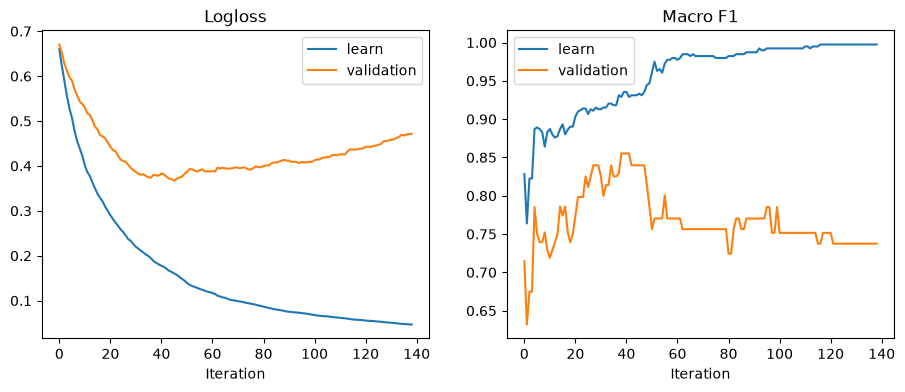

In [17]:
def summarize(records,include_tail=False):
    valid=[r for r in records if r['gt_label'] in [0,1] and (include_tail or not r['has_tail'])]
    assert valid
    y=[r['gt_label'] for r in valid];pred=[r['prediction'] for r in valid]
    precision,recall,f1,support=precision_recall_fscore_support(y,pred,labels=[0,1],zero_division=0)
    result=dict(macro_f1=float(f1_score(y,pred,labels=[0,1],average='macro',zero_division=0)),
        balanced_accuracy=float(balanced_accuracy_score(y,pred)))
    for i,name in enumerate(['spoken','narrated']):
        result.update({name+'_precision':float(precision[i]),name+'_recall':float(recall[i]),
            name+'_f1':float(f1[i]),name+'_support':int(support[i])})
        p=[r['p_spoken'] if i==0 else r['p_narrated'] for r in valid if r['gt_label']==i]
        if p:result[name+'_p_true_mean']=float(np.mean(p));result[name+'_p_true_p10']=float(np.quantile(p,.1))
    return result


predictions=[]
for sample in val:
    selected=[i for i,u in enumerate(sample['units']) if not u['has_tail']]
    probs={}
    if selected:
        frame=pd.DataFrame(sample['X'][selected],columns=COLUMNS)
        probs=dict(zip(selected,model.predict_proba(frame).tolist()))
    for i,unit in enumerate(sample['units']):
        p=[1.,0.] if unit['has_tail'] else probs[i]
        predictions.append(dict(sequence_id=sample['sequence_id'],box_id=unit['box_id'],box_ids=unit['box_ids'],
            text=unit['text'],gt_label=unit['gt_label'],has_tail=unit['has_tail'],
            route='tail_forced_spoken' if unit['has_tail'] else 'catboost',
            prediction=int(np.argmax(p)),p_spoken=p[0],p_narrated=p[1],
            heuristic_role=unit['heuristic_role'],heuristic_reason=unit['heuristic_reason']))
no_tail=summarize(predictions)
overall=summarize(predictions,include_tail=True)
heuristic=summarize([dict(r,prediction=0 if r['heuristic_role']=='SPOKEN' else 1) for r in predictions])
display(pd.DataFrame([dict(method='Heuristic, no tail',**heuristic),
    dict(method='CatBoost, no tail',**no_tail),dict(method='CatBoost + tail rule, all known units',**overall)]))
pd.DataFrame(predictions).to_csv(RUN/'val_predictions.csv',index=False)
save_json(RUN/'val_predictions.json',predictions)
save_json(RUN/'evaluation.json',dict(no_tail=no_tail,overall=overall,heuristic=heuristic,best_iteration=model.get_best_iteration()))
save_json(RUN/'config.json',dict(features=COLUMNS,base_features=FEATURE_NAMES,
    units={s['sequence_id']:s['signature'] for s in unit_sequences},
    helper=HELPER_ID,bubble_weights=BUBBLE_SHA,bubble_settings=BUBBLE_SETTINGS,
    class_order=['SPOKEN','NARRATED'],no_tail_targets_only=True,context=2,semantics=False,
    missing_values='NaN from availability flags; no standardization',
    split=dict(train=sorted(train_ids),validation=sorted(val_ids)),
    seed=SEED,iterations=ITERATIONS,depth=DEPTH,learning_rate=LEARNING_RATE,l2_leaf_reg=L2_LEAF_REG,
    beta=BETA,train_counts=counts.tolist(),class_weights=class_weights,
    narration_sequence_weight=NARRATION_SEQUENCE_WEIGHT,
    catboost_version=__import__('catboost').__version__))
# Plot training/validation curves; macro F1 selection ignores class weights.
curves=model.get_evals_result()
fig,axes=plt.subplots(1,2,figsize=(11,4))
for split,metrics in curves.items():
    if 'Logloss' in metrics:axes[0].plot(metrics['Logloss'],label=split)
    for metric,values in metrics.items():
        if metric.startswith('TotalF1'):axes[1].plot(values,label=split)
axes[0].set_title('Logloss');axes[1].set_title('Macro F1')
for ax in axes:ax.set_xlabel('Iteration');ax.legend()
plt.show();plt.close(fig)


## 8. Feature importance and optional per-text explanation
Global importance ranks measurements used by the model; it does not establish causality. For one no-tail text, SHAP contributions explain its raw narration score: positive pushes toward NARRATED, negative toward SPOKEN. Call `explain_text(sequence_id, box_id)` manually.

,feature,importance
15,current__box_axis_fraction,15.115697
16,current__box_like,8.906716
7,current__sharp_fraction,8.071202
6,current__flat_fraction,6.960712
11,current__curve_turn_deg,5.134152
14,current__rectangularity,4.862842
1,current__solid_fraction,4.252405
10,current__curve_arc_px,4.233430
12,current__curve_bulge_px,4.057997
8,current__curve_run,3.615887


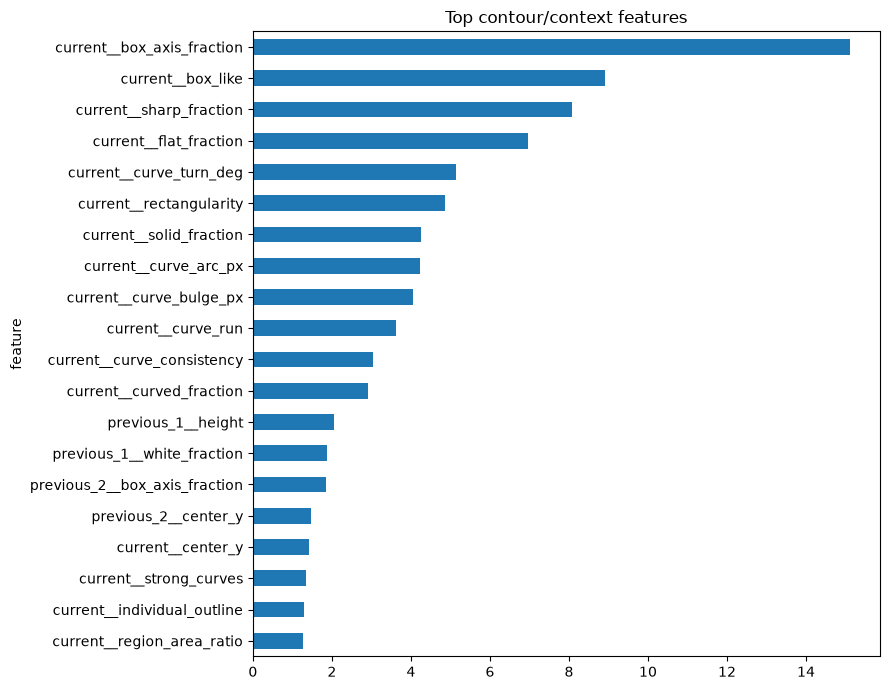

Model: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\ContourNarrationCatBoost\runs\comparison_seed42\baseline_double\best.cbm
Predictions: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\ContourNarrationCatBoost\runs\comparison_seed42\baseline_double\val_predictions.csv


In [18]:
importance=pd.DataFrame(dict(feature=COLUMNS,importance=model.get_feature_importance())).sort_values('importance',ascending=False)
importance.to_csv(RUN/'feature_importance.csv',index=False)
display(importance.head(20))
fig,ax=plt.subplots(figsize=(9,7))
importance.head(20).iloc[::-1].plot.barh(x='feature',y='importance',ax=ax,legend=False)
ax.set_title('Top contour/context features');plt.tight_layout();plt.show();plt.close(fig)


def explain_text(sequence_id,box_id):
    sample=next(s for s in samples if s['sequence_id']==sequence_id)
    index=next(i for i,u in enumerate(sample['units']) if u['box_id']==box_id)
    unit=sample['units'][index]
    if unit['has_tail']:
        print('Tail-linked: forced SPOKEN; CatBoost is bypassed.');return
    frame=pd.DataFrame(sample['X'][[index]],columns=COLUMNS)
    probabilities=model.predict_proba(frame)[0]
    shap=model.get_feature_importance(Pool(frame),type='ShapValues')[0]
    explanation=pd.DataFrame(dict(feature=COLUMNS,value=frame.iloc[0].values,
        narration_score_contribution=shap[:-1]))
    explanation['magnitude']=explanation['narration_score_contribution'].abs()
    explanation=explanation.sort_values('magnitude',ascending=False)
    print(unit['text'])
    print('P(SPOKEN):',round(float(probabilities[0]),4),'| P(NARRATED):',round(float(probabilities[1]),4))
    print('SHAP baseline:',round(float(shap[-1]),4),'| positive = narration; negative = spoken')
    display(explanation.head(15))

# Optional: explain_text('seq_...', 'PG2:T8')
print('Model:',RUN/'best.cbm')
print('Predictions:',RUN/'val_predictions.csv')


## 9. Balancing comparison and optional text features
Keep the numeric baseline above for a controlled comparison. Its new output directory is `runs/comparison_seed42/baseline_double`; the original `runs/baseline_seed42` is untouched.

Train two alternatives: **oversampling only** (equal class weights), and **class weights only** (one copy per sequence). With `USE_TEXT_VARIANTS=True`, repeat both with frozen DeBERTa context. The same split, original GT labels, tail exclusion, seed, depth and learning rate apply to every run.

Text variants use previous-two + current frozen DeBERTa embeddings, reduced to 16 PCA components fitted on original labelled no-tail training units only. This tests whether semantics resolves visually similar spoken/caption boxes. Existing compatible MLP semantic caches are reused read-only. No validation data fits PCA. Numeric-only runs require no text model.

In [19]:
if USE_TEXT_VARIANTS:
    assert DEBERTA_PATH.is_dir(),DEBERTA_PATH
    TEXT_ID=model_identity(DEBERTA_PATH)
    encoder=None;tokenizer=None
    try:
        for seq in unit_sequences:
            signature=digest(dict(units=[(u['box_id'],u['page_index'],u['text']) for u in seq['units']],
                model=str(DEBERTA_PATH),files=TEXT_ID,max_tokens=MAX_TOKENS,context=2,pool='target_mean_v1'))
            path=CACHE/'semantics'/(seq['sequence_id']+'.pt')
            saved=None
            for candidate_path in [path,SHARED_CONTOUR_CACHE/'semantics'/(seq['sequence_id']+'.pt')]:
                if candidate_path.is_file():
                    candidate=torch.load(candidate_path,map_location='cpu',weights_only=True)
                    if candidate.get('signature')==signature:
                        saved=candidate;break
            if saved and saved['signature']==signature and not FORCE_SEMANTICS:
                seq['semantic']=saved['vectors'];continue
            if encoder is None:
                from transformers import AutoTokenizer,AutoModel
                tokenizer=AutoTokenizer.from_pretrained(str(DEBERTA_PATH),local_files_only=True)
                encoder=AutoModel.from_pretrained(str(DEBERTA_PATH),local_files_only=True).to(DEVICE).eval()
                encoder.requires_grad_(False)
                assert encoder.config.hidden_size==768
            history={0:[],1:[],2:[]};items=[]
            for unit in seq['units']:
                context=[]
                for text in history[unit['page_index']][-2:]:
                    context+=tokenizer.encode(text,add_special_tokens=False)+[tokenizer.sep_token_id]
                target=tokenizer.encode(unit['text'],add_special_tokens=False) or [tokenizer.unk_token_id]
                budget=MAX_TOKENS-2;assert budget>0
                target=target[-budget:];remaining=budget-len(target)
                context=context[-remaining:] if remaining else []
                ids=[tokenizer.cls_token_id]+context+target+[tokenizer.sep_token_id]
                mask=[0]*(1+len(context))+[1]*len(target)+[0]
                items.append((ids,mask));history[unit['page_index']].append(unit['text'])
            vectors=[]
            with torch.inference_mode():
                for start in range(0,len(items),TEXT_BATCH_SIZE):
                    batch=items[start:start+TEXT_BATCH_SIZE];length=max(len(v[0]) for v in batch)
                    ids=torch.full((len(batch),length),tokenizer.pad_token_id,dtype=torch.long,device=DEVICE)
                    attention=torch.zeros_like(ids);target_mask=torch.zeros_like(ids,dtype=torch.float)
                    for i,(tokens,mask) in enumerate(batch):
                        ids[i,:len(tokens)]=torch.tensor(tokens,device=DEVICE)
                        attention[i,:len(tokens)]=1;target_mask[i,:len(tokens)]=torch.tensor(mask,device=DEVICE)
                    hidden=encoder(input_ids=ids,attention_mask=attention).last_hidden_state
                    pooled=(hidden*target_mask.unsqueeze(-1)).sum(1)/target_mask.sum(1,keepdim=True)
                    vectors.extend(pooled.float().cpu().unbind())
            matrix=torch.stack(vectors) if vectors else torch.empty(0,768)
            path.parent.mkdir(parents=True,exist_ok=True)
            torch.save(dict(signature=signature,vectors=matrix),path)
            seq['semantic']=matrix;print('SEMANTICS',seq['sequence_id'],len(matrix))
    finally:
        encoder=None;tokenizer=None;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()

TEXT_COLUMNS=[]
text_pca=None
if USE_TEXT_VARIANTS:
    from sklearn.decomposition import PCA
    import joblib
    semantic_by_id={s['sequence_id']:s['semantic'].numpy() for s in unit_sequences}
    original_train_text=np.concatenate([semantic_by_id[s['sequence_id']][
        [i for i,u in enumerate(s['units']) if u['label'] in [0,1]]] for s in train])
    components=min(TEXT_PCA_DIM,original_train_text.shape[0]-1,original_train_text.shape[1])
    assert components>=1
    text_pca=PCA(n_components=components,random_state=SEED)
    text_pca.fit(original_train_text)
    TEXT_COLUMNS=[f'deberta_pca_{i+1}' for i in range(components)]
    for sample in samples:
        semantic=semantic_by_id[sample['sequence_id']]
        assert len(semantic)==len(sample['units'])
        projected=text_pca.transform(semantic) if len(semantic) else np.empty((0,components))
        sample['X_text']=np.concatenate([sample['X'],projected],axis=1)
    joblib.dump(text_pca,COMPARISON_ROOT/'text_pca.joblib')
    print('Text PCA components:',components,'| train-only explained variance:',round(float(text_pca.explained_variance_ratio_.sum()),3))


Text PCA components: 16 | train-only explained variance: 0.804


## 10. Train and compare variants — you run this cell
Each alternative writes its own native model, metadata, sampling audit, predictions and evaluation. Both text variants use exactly the same train-only PCA. Validation macro F1 is unweighted, and thresholds remain 0.5. This is a validation comparison, not an independent test estimate. Inspect precision and recall together rather than selecting on precision alone.

In [20]:
# The baseline model and its results were created by cells 6-8 above.
variant_models={'baseline_double':model}
variant_info={'baseline_double':dict(use_text=False,oversample=True,class_weights=class_weights)}
variant_predictions={'baseline_double':predictions}
comparison_metrics=[dict(variant='baseline_double',**no_tail)]
variants=[dict(name='oversampling_only',oversample=True,weighted=False,use_text=False),
          dict(name='class_weights_only',oversample=False,weighted=True,use_text=False)]
if USE_TEXT_VARIANTS:
    variants += [dict(name='oversampling_only_text',oversample=True,weighted=False,use_text=True),
                 dict(name='class_weights_only_text',oversample=False,weighted=True,use_text=True)]
copies_by_id={r['sequence_id']:r['copies'] for r in sampling_audit}


def variant_frame(sample,indices,use_text):
    values=sample['X_text'] if use_text else sample['X']
    return pd.DataFrame(values[indices],columns=COLUMNS+(TEXT_COLUMNS if use_text else []))


def predict_sequence(fitted,sample,use_text):
    # Every tail-linked unit bypasses the classifier, including in the viewer.
    indices=[i for i,u in enumerate(sample['units']) if not u['has_tail']]
    probs=dict(zip(indices,fitted.predict_proba(variant_frame(sample,indices,use_text)).tolist())) if indices else {}
    output=[]
    for i,unit in enumerate(sample['units']):
        p=[1.,0.] if unit['has_tail'] else probs[i]
        output.append(dict(sequence_id=sample['sequence_id'],box_id=unit['box_id'],box_ids=unit['box_ids'],
            page_index=unit['page_index'],text=unit['text'],gt_label=unit['gt_label'],has_tail=unit['has_tail'],
            route='tail_forced_spoken' if unit['has_tail'] else 'catboost',prediction=int(np.argmax(p)),
            p_spoken=p[0],p_narrated=p[1],heuristic_role=unit['heuristic_role'],heuristic_reason=unit['heuristic_reason']))
    return output


for variant in variants:
    directory=COMPARISON_ROOT/variant['name'];directory.mkdir(parents=True,exist_ok=True)
    train_frames=[];train_labels=[];audit=[]
    for sample in train:
        indices=[i for i,u in enumerate(sample['units']) if u['label'] in [0,1]]
        assert all(not sample['units'][i]['has_tail'] for i in indices)
        copies=copies_by_id[sample['sequence_id']] if variant['oversample'] else 1
        for _ in range(copies):
            train_frames.append(variant_frame(sample,indices,variant['use_text']))
            train_labels.extend(sample['units'][i]['label'] for i in indices)
        audit.append(dict(sequence_id=sample['sequence_id'],copies=copies,targets=len(indices)))
    validation_frames=[];validation_labels=[]
    for sample in val:
        indices=[i for i,u in enumerate(sample['units']) if u['label'] in [0,1]]
        if indices:
            validation_frames.append(variant_frame(sample,indices,variant['use_text']))
            validation_labels.extend(sample['units'][i]['label'] for i in indices)
    fitted=CatBoostClassifier(iterations=ITERATIONS,depth=DEPTH,learning_rate=LEARNING_RATE,
        l2_leaf_reg=L2_LEAF_REG,loss_function='Logloss',
        eval_metric='TotalF1:average=Macro;use_weights=false',
        class_weights=class_weights if variant['weighted'] else [1.,1.],
        nan_mode='Min',random_seed=SEED,task_type='CPU',train_dir=str(directory/'catboost_logs'),verbose=50)
    fitted.fit(pd.concat(train_frames,ignore_index=True),np.asarray(train_labels),
        eval_set=(pd.concat(validation_frames,ignore_index=True),np.asarray(validation_labels)),
        early_stopping_rounds=EARLY_STOPPING,use_best_model=True)
    fitted.save_model(str(directory/'best.cbm'))
    records=[row for sample in val for row in predict_sequence(fitted,sample,variant['use_text'])]
    metrics=summarize(records)
    metrics.update(true_positives=sum(r['gt_label']==1 and r['prediction']==1 for r in records if not r['has_tail']),
        false_positives=sum(r['gt_label']==0 and r['prediction']==1 for r in records if not r['has_tail']),
        false_negatives=sum(r['gt_label']==1 and r['prediction']==0 for r in records if not r['has_tail']))
    save_json(directory/'evaluation.json',dict(no_tail=metrics,overall=summarize(records,include_tail=True)))
    save_json(directory/'sampling_audit.json',audit)
    save_json(directory/'val_predictions.json',records)
    pd.DataFrame(records).to_csv(directory/'val_predictions.csv',index=False)
    metadata=json.loads((RUN/'config.json').read_text(encoding='utf-8'))
    metadata.update(variant=variant,features=COLUMNS+(TEXT_COLUMNS if variant['use_text'] else []),
        semantics=variant['use_text'],class_weights=class_weights if variant['weighted'] else [1.,1.],
        narration_sequence_weight=NARRATION_SEQUENCE_WEIGHT if variant['oversample'] else 1.,
        semantic_model=str(DEBERTA_PATH) if variant['use_text'] else None,
        semantic_model_files=TEXT_ID if variant['use_text'] else None,
        text_pca_path=str(COMPARISON_ROOT/'text_pca.joblib') if variant['use_text'] else None,
        semantic_pool='target_mean_v1' if variant['use_text'] else None,max_tokens=MAX_TOKENS,
        best_iteration=fitted.get_best_iteration())
    save_json(directory/'config.json',metadata)
    variant_models[variant['name']]=fitted
    variant_info[variant['name']]=variant
    variant_predictions[variant['name']]=records
    comparison_metrics.append(dict(variant=variant['name'],**metrics))

# Add raw counts to the baseline row too.
base=variant_predictions['baseline_double']
comparison_metrics[0].update(
    true_positives=sum(r['gt_label']==1 and r['prediction']==1 for r in base if not r['has_tail']),
    false_positives=sum(r['gt_label']==0 and r['prediction']==1 for r in base if not r['has_tail']),
    false_negatives=sum(r['gt_label']==1 and r['prediction']==0 for r in base if not r['has_tail']))
variant_comparison=pd.DataFrame(comparison_metrics)
variant_comparison.to_csv(COMPARISON_ROOT/'comparison.csv',index=False)
display(variant_comparison[['variant','narrated_precision','narrated_recall','narrated_f1','macro_f1',
    'true_positives','false_positives','false_negatives']])
print('Separate runs:',COMPARISON_ROOT)


0:	learn: 0.8538392	test: 0.6306981	best: 0.6306981 (0)	total: 1.9ms	remaining: 1.9s
50:	learn: 0.9242474	test: 0.6536490	best: 0.6536490 (2)	total: 94.8ms	remaining: 1.76s
100:	learn: 0.9789609	test: 0.6536490	best: 0.6536490 (2)	total: 184ms	remaining: 1.64s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.6536490115
bestIteration = 2

Shrink model to first 3 iterations.
0:	learn: 0.8107107	test: 0.6394410	best: 0.6394410 (0)	total: 2.58ms	remaining: 2.58s
50:	learn: 0.9497131	test: 0.6416667	best: 0.7243590 (2)	total: 102ms	remaining: 1.9s
100:	learn: 0.9885269	test: 0.7289916	best: 0.7667269 (62)	total: 242ms	remaining: 2.15s
150:	learn: 0.9942116	test: 0.6875138	best: 0.7667269 (62)	total: 349ms	remaining: 1.96s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.7667269439
bestIteration = 62

Shrink model to first 63 iterations.
0:	learn: 0.8503452	test: 0.6416667	best: 0.6416667 (0)	total: 3.18ms	remaining: 3.18s
50:	learn: 0.9452561	test: 0.

,variant,narrated_precision,narrated_recall,narrated_f1,macro_f1,true_positives,false_positives,false_negatives
0,baseline_double,0.666667,0.833333,0.740741,0.855219,10,5,2
1,oversampling_only,0.600000,0.250000,0.352941,0.653649,3,2,9
2,class_weights_only,0.666667,0.500000,0.571429,0.766727,6,3,6
3,oversampling_only_text,0.600000,0.250000,0.352941,0.653649,3,2,9
4,class_weights_only_text,0.714286,0.416667,0.526316,0.744329,5,2,7


Separate runs: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\ContourNarrationCatBoost\runs\comparison_seed42


## 11. Sequence/page viewer and error inspection
Select a run, sequence and page. One page image is rendered at a time. Training sequences are explicitly labelled; their results are not held-out performance. Default sequence comes from validation. Yellow=NARRATED, blue=SPOKEN; red marks a wrong known-GT role. Tail-routed units are labelled TAIL. Use the filter to isolate false-positive narration or missed narration.

The table includes the actual text, GT role, narration probability and contour reason so confident mistakes can be checked against the image. Dashed rectangles show original member boxes. No contour extraction or model training occurs in this viewer.

In [21]:
from io import BytesIO
from IPython.display import Image as DisplayImage,clear_output
from matplotlib.patches import Rectangle
import ipywidgets as widgets
source_sequences={s['sequence_id']:s for s in sequences}
sample_lookup={s['sequence_id']:s for s in samples}
viewer_predictions={}


def view_sequence_page(variant,sequence_id,page_number,filter_name='All'):
    sample=sample_lookup[sequence_id];source=source_sequences[sequence_id]
    key=(variant,sequence_id)
    if key not in viewer_predictions:
        viewer_predictions[key]=predict_sequence(variant_models[variant],sample,variant_info[variant]['use_text'])
    page_index=int(page_number)-1
    records=[r for r in viewer_predictions[key] if r['page_index']==page_index]
    boxes={b['box_id']:b['bbox'] for b in source['boxes']}
    table=[]
    with Image.open(source['pages'][page_index]['path']) as image:
        fig,ax=plt.subplots(figsize=(11,15));ax.imshow(image.convert('RGB'))
    for row in records:
        gt=row['gt_label'];prediction=row['prediction']
        fp=gt==0 and prediction==1;fn=gt==1 and prediction==0
        wrong=gt in [0,1] and gt!=prediction
        if filter_name=='False-positive narration' and not fp:continue
        if filter_name=='Missed narration' and not fn:continue
        if filter_name=='All errors' and not wrong:continue
        member_boxes=[boxes[bid] for bid in row['box_ids']]
        a=min(b[0] for b in member_boxes);b=min(b[1] for b in member_boxes)
        c=max(b[2] for b in member_boxes);d=max(b[3] for b in member_boxes)
        color='gold' if prediction==1 else 'dodgerblue'
        ax.add_patch(Rectangle((a,b),c-a,d-b,fill=False,edgecolor='red' if wrong else color,linewidth=2))
        for x1,y1,x2,y2 in member_boxes:
            ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor=color,linestyle='--',linewidth=1))
        role='NARRATED' if prediction==1 else 'SPOKEN'
        label=row['box_id']+' '+role+f" pN={row['p_narrated']:.2f}"+(' TAIL' if row['has_tail'] else '')
        ax.text(a,b,label,fontsize=8,bbox=dict(facecolor='salmon' if wrong else color,alpha=.85))
        table.append(dict(box_id=row['box_id'],text=row['text'],prediction=role,
            GT='SPOKEN' if gt==0 else 'NARRATED' if gt==1 else 'IGNORED',
            p_narrated=round(row['p_narrated'],4),tail=row['has_tail'],false_positive=fp,false_negative=fn,
            contour_reason=row['heuristic_reason']))
    split='VALIDATION' if sequence_id in val_ids else 'TRAINING (not held out)'
    ax.set_title(variant+' | '+split+' | '+sequence_id+' | page '+str(page_number))
    ax.axis('off');buffer=BytesIO()
    try:fig.savefig(buffer,format='png',bbox_inches='tight',dpi=100)
    finally:plt.close(fig)
    display(DisplayImage(data=buffer.getvalue()))
    display(pd.DataFrame(table))


# Close old widget callbacks and output on cell reruns.
old=globals().get('_catboost_viewer')
if old:
    for widget in old[:4]:widget.unobserve_all()
    for widget in old:widget.close()
clear_output(wait=True)
variant_picker=widgets.Dropdown(options=list(variant_models),description='Run')
sequence_options=[(sid+(' [VAL]' if sid in val_ids else ' [TRAIN]'),sid) for sid in sorted(sample_lookup)]
default_sequence=next(s['sequence_id'] for s in val)
sequence_picker=widgets.Dropdown(options=sequence_options,value=default_sequence,description='Sequence',
    layout=widgets.Layout(width='470px'))
page_picker=widgets.Dropdown(options=[1,2,3],value=1,description='Page')
filter_picker=widgets.Dropdown(options=['All','All errors','False-positive narration','Missed narration'],description='Show')
viewer_output=widgets.Output()


def refresh_viewer(change=None):
    with viewer_output:
        clear_output(wait=True)
        view_sequence_page(variant_picker.value,sequence_picker.value,page_picker.value,filter_picker.value)


for picker in [variant_picker,sequence_picker,page_picker,filter_picker]:picker.observe(refresh_viewer,names='value')
viewer_panel=widgets.VBox([widgets.HBox([variant_picker,page_picker]),sequence_picker,filter_picker,viewer_output])
_catboost_viewer=[variant_picker,sequence_picker,page_picker,filter_picker,viewer_output,viewer_panel]
display(viewer_panel);refresh_viewer()
